In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pywt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import sys
import os

from wavelets import WaveletTransformOperator2D

import jlinops




from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])




from msolver import IASGKS, MMGKS, VanillaGKS
from fsolver import MMFGK
from f2019solver import MMFGK2019
from pgkbsolver import MMGKB

# Setup toy problem

In [2]:
image = jlinops.cameraman()
img_shape = image.shape
ground_truth = image.flatten()

A = jlinops.Gaussian2DBlurOperator(img_shape, blur_sigma=2.0, mode="reflect")
#A = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
b_true = A @ ground_truth
noise_level_sigma = 0.03
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
noise_sigma = np.sqrt(noise_var)
b = b_true + noise_vec
naive_recon = A.T @ b

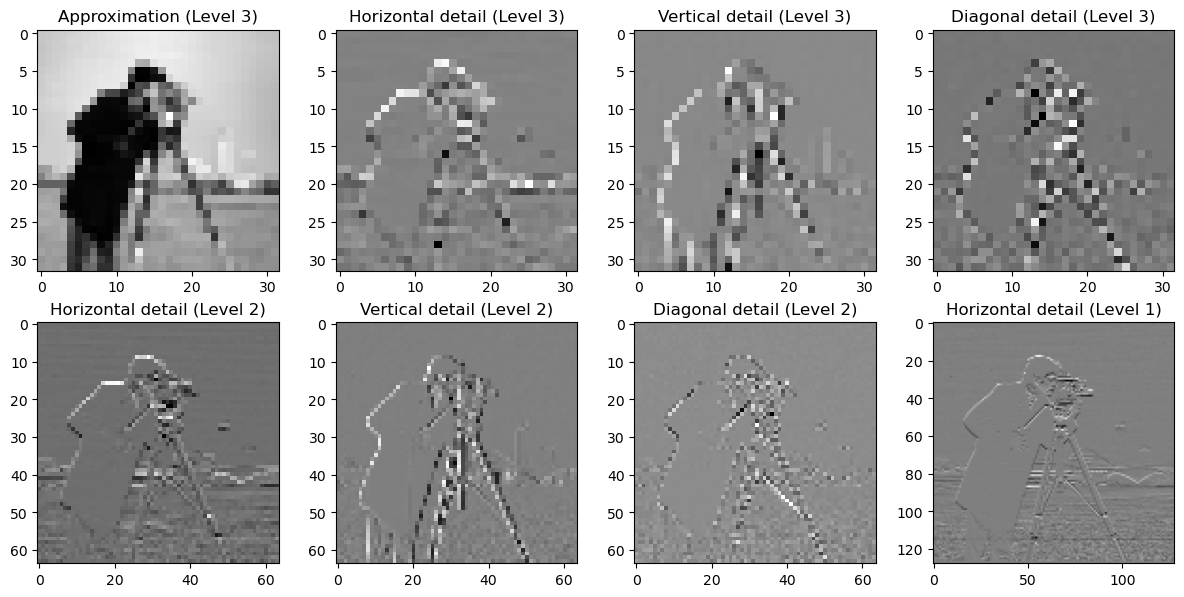

In [3]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(image, 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


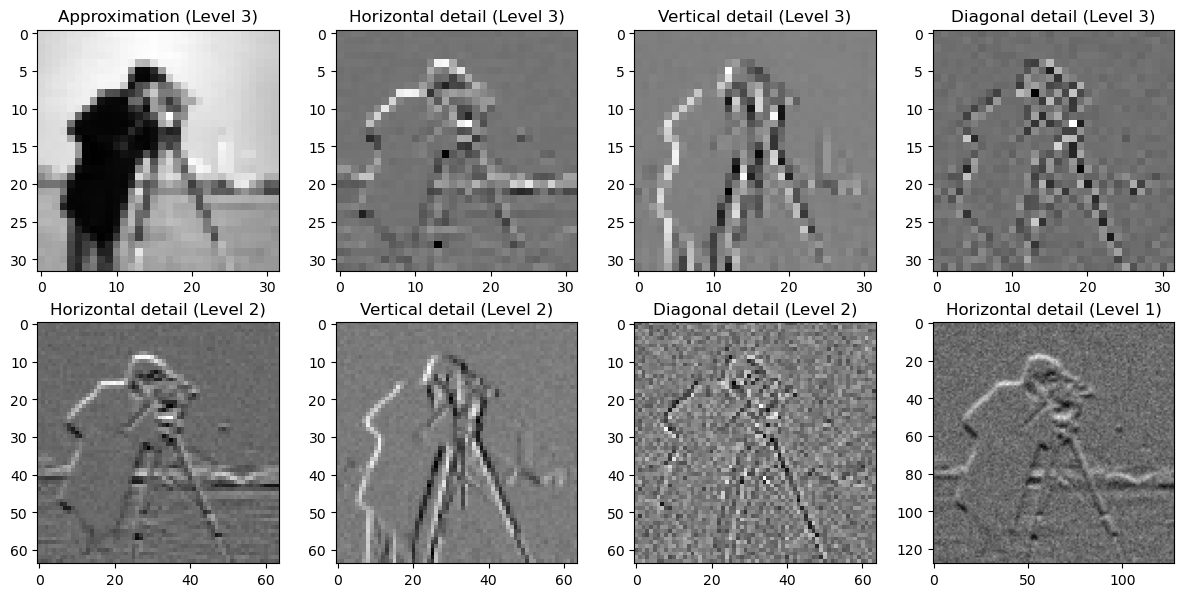

In [4]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(b.reshape(img_shape), 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


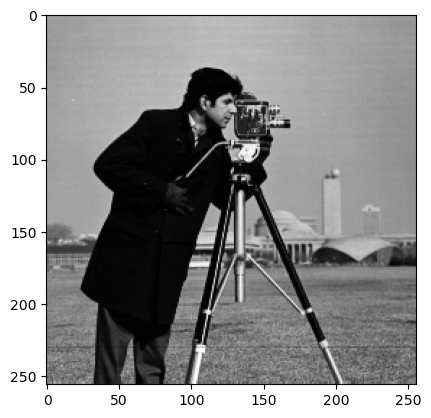

In [5]:
plt.imshow(image, cmap="gray")
plt.show()

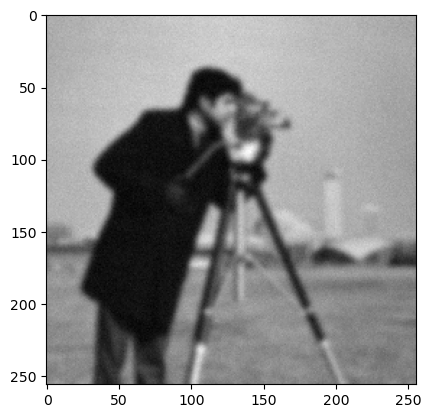

In [6]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

# Set up prior

In [7]:
# This can be figured out later
# mask = np.zeros(Lpre.shape[0])
# mask[ Lpre.detail_indices ] = 1
# P = jlinops.Subsampling1DOperator(mask)
#L = P @ Lpre

L = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
K = None
Lpinv_factory = lambda wr: L.T @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

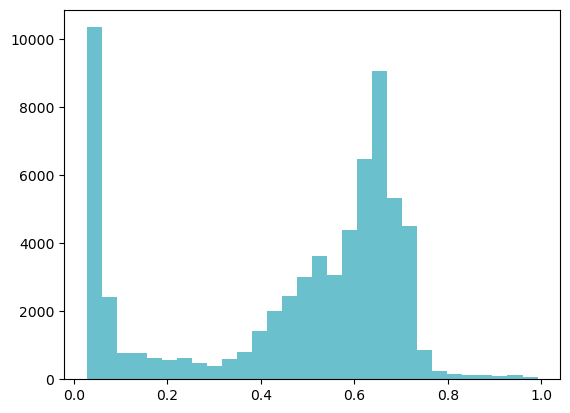

In [8]:
plt.hist(ground_truth, bins=30)
plt.show()

In [9]:
# Set method
method = "dp"

# Weight params
q = 1.0
epsilon = 1e-4
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

# Build solver
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmfk_solver = MMFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmfk2019_solver = MMFGK2019(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmgkb_solver = MMGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

xker = None
ground_truth = ground_truth.copy()

In [10]:
n_its = 150

vdata = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params={},
                                    regparam_kwargs={"eta":1.01},  xker=xker)

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params, 
                                                 regparam_kwargs={"eta":1.01})


data = mmgks_solver.solve(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)


mmfkdata = mmfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

mmfkdata = mmfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )


mmfk2019Idata = mmfk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )


mmfk2019Rdata = mmfk2019_solver.solve(n_iter=n_its, x0=None, mode="R", lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )


mmfk2019Wdata = mmfk2019_solver.solve(n_iter=n_its, x0=None, mode="W", lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )



rmmfkdata = mmfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params, refresh_basis=True,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )



mmgkbdata = mmgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=weight_params,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished P-GKB")



1e-07
22.988563187270334
29.6930894086289
33.49197759905139
35.8167610971918
37.32672782180556
38.376341455397274
39.12508135564832
39.642092503291664
40.01095573330812
40.2749307837277
40.46606263727531
40.60472447816086
40.70517896820218
40.77472749584616
40.825019469924335
40.86097262865215
40.88689579156875
40.90535387646723
40.91860354921644
40.9282523295581
40.93472396437045
40.93924515272606
40.942457698751156
40.94467704105532
40.94621355602504
40.94731326168212
40.948092145087514
40.94862427775749
40.94900211067714
40.949258039560874
40.9494410391377
40.94956984064931
40.949658897595675
40.94972037464508
40.94976191172337
40.9497910301866
40.94981094643195
40.94982425688887
40.94983299417149
40.94983935978766
40.94984391648323
40.94984705087223
40.9498491530558
40.94985061359175
40.94985161206986
40.94985230682109
40.949852773634746
40.9498530964694
40.94985331772222
40.94985347119584
40.94985357997116
40.9498536541986
40.94985370339387
40.94985373679806
40.94985375965389
40.9

1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/tests/2d_blur_wavelets/../../msolver.py:800: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
4.077671315242397
7.011369769343004
8.552540960890882
9.764760792596032
10.837781709308755
11.77478153527666
12.514583777536451
13.172897161863986
13.776687818370462
14.268348550437942
14.699283743260466
15.086176474010838
15.422091269688655
15.701239755685934
15.97924422284067
16.26832899218708
16.5373010062342
16.772148372493476
17.00380928401118
17.254062460638703
17.486948402333454
17.66708104737234
17.851270643574647
18.043405755839252
18.217052021517638
18.384348623925206
18.5116767166259
18.62619311874745
18.734477944399863
18.84623998982493
18.949011168117462


40.11640843549612
17.05752608760526
24.526219574515537
23.46971586955073
21.844104544875385
21.877622399500755
21.80682601994563
21.116143353243636
20.211656488993476
20.27185553803821
19.98340891279334
19.57495542973015
19.78548483104054
19.617841128231998
19.54355293276869
19.67849093136816
19.656177363791954
19.902413716187706
19.92966628276512
20.094668997221525
20.02285873629357
20.065777366062246
20.012515782420095
19.976539528025796
19.976930516110404
19.79178918033813
19.851001875243877
19.78843288452537
19.965853121675128
20.065301972058975
20.068132319404004
19.847061058756616
19.627780923284863
19.48046786083442
19.29875254935823
19.229760179654182
19.17562587207267
19.132502622770154
19.116089573807088
19.120924045530547
19.098769159529507
19.081280958305186
19.0858920359118
19.07679894310082
19.072170666713244
19.06709030783068
19.06479193660088
19.054698458241116
19.039525308325675
19.034992438246185
19.03175646798415
19.03226052237359
19.024389694824617
19.03341129278360

...

generating basis...: 100%|██████████| 149/149 [00:02<00:00, 57.83it/s]

20.86669128250232



generating basis...: 100%|██████████| 150/150 [00:02<00:00, 57.67it/s]

20.86972844757384


Finished P-GKB


# Performance

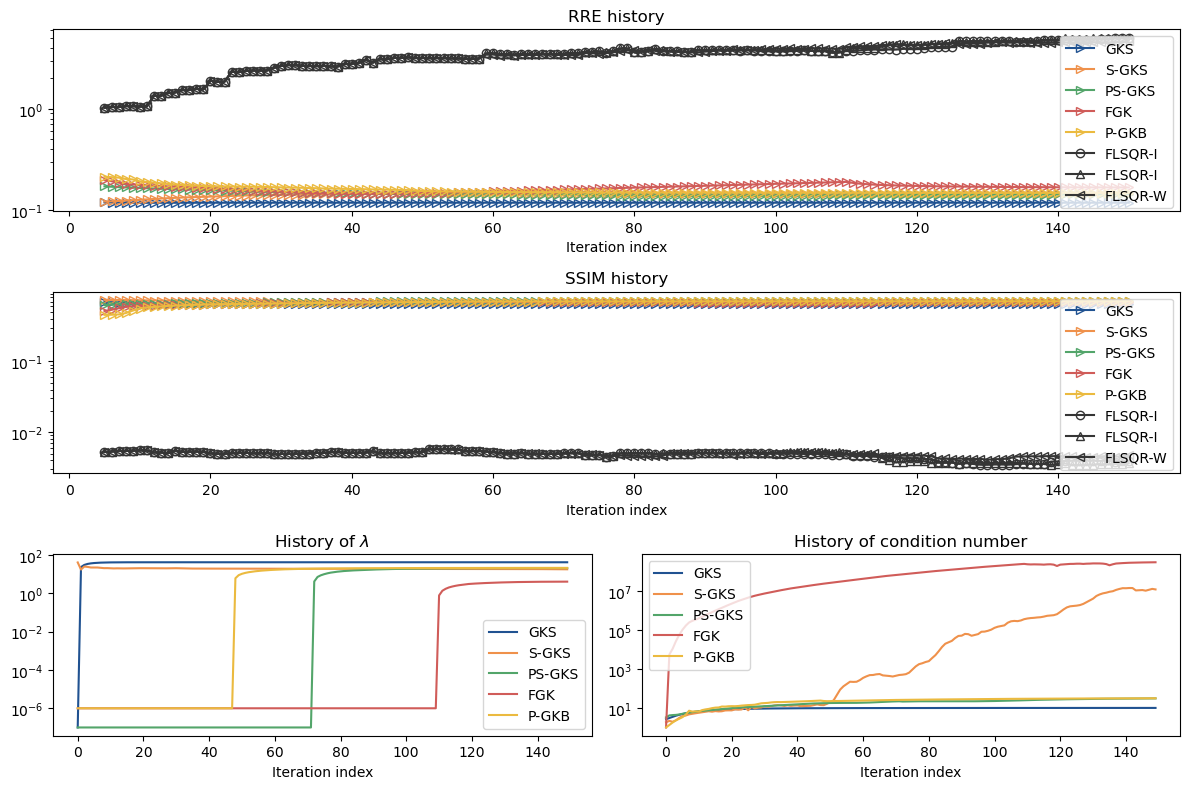

In [19]:
fig = plt.figure(figsize=(12,8) )

gs = gridspec.GridSpec(3, 2, figure=fig)

start_idx = 5
marker = ">"
markerfacecolor = 'none'

ax4 = fig.add_subplot(gs[0, :])
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))],  vdata["rre_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["rre_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["rre_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["rre_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["rre_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Idata["rre_history"][start_idx:], label="FLSQR-I", color="C9", marker="o", markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Rdata["rre_history"][start_idx:], label="FLSQR-I", color="C9", marker="^", markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Wdata["rre_history"][start_idx:], label="FLSQR-W", color="C9", marker="<", markerfacecolor=markerfacecolor)
ax4.legend()
ax4.set_xlabel("Iteration index")
ax4.set_title("RRE history")



ax3 = fig.add_subplot(gs[1, :])
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], vdata["ssim_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["ssim_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["ssim_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["ssim_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["ssim_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Idata["ssim_history"][start_idx:], label="FLSQR-I", color="C9", marker="o", markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Rdata["ssim_history"][start_idx:], label="FLSQR-I", color="C9", marker="^", markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Wdata["ssim_history"][start_idx:], label="FLSQR-W", color="C9", marker="<", markerfacecolor=markerfacecolor)
ax3.legend()
ax3.set_xlabel("Iteration index")
ax3.set_title("SSIM history")

# ax3 = fig.add_subplot(gs[1, :])
# ax3.semilogy(vdata["haar_history"][start_idx:], label="GKS")
# ax3.semilogy(data["haar_history"][start_idx:], label="S-GKS")
# ax3.semilogy(pdata["haar_history"][start_idx:], label="PS-GKS")
# ax3.semilogy(mmfkdata["haar_history"][start_idx:], label="FGK")
# ax3.semilogy(mmgkbdata["haar_history"][start_idx:], label="P-GKB")
# ax3.legend()


ax1 = fig.add_subplot(gs[2, 0])
ax1.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax1.semilogy(data["lambda_history"], label="S-GKS", color="C5")
ax1.semilogy(pdata["lambda_history"], label="PS-GKS", color="C4")
ax1.semilogy(mmfkdata["lambda_history"], label="FGK", color="C6")
ax1.semilogy(mmgkbdata["lambda_history"], label="P-GKB", color="C1")
ax1.legend(loc="lower right")
ax1.set_title("History of $\lambda$")
ax1.set_xlabel("Iteration index")



ax2 = fig.add_subplot(gs[2, 1])
ax2.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax2.semilogy(data["cond_ests"], label="S-GKS", color="C5")
ax2.semilogy(pdata["cond_ests"], label="PS-GKS", color="C4")
ax2.semilogy(mmfkdata["cond_ests"], label="FGK", color="C6")
ax2.semilogy(mmgkbdata["cond_ests"], label="P-GKB", color="C1")
ax2.legend(loc="upper left")
ax2.set_title("History of condition number")
ax2.set_xlabel("Iteration index")

fig.tight_layout()
fig.savefig("2d_camera_performance_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_performance_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Reconstruction

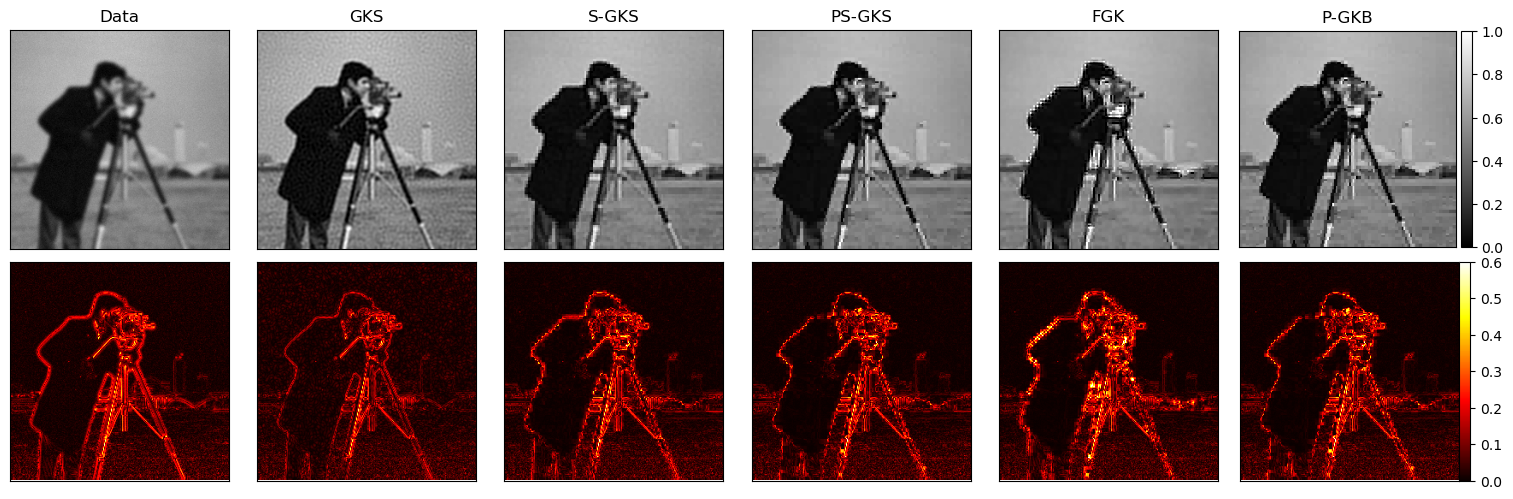

In [239]:
err_cmap = "hot"

vbound = 0.6

fig, axs = plt.subplots(2,6,figsize=(15.3,5))


# Observed
axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,0].set_title("Data")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])



# Tikhonov
axs[0,1].imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,1].set_title("GKS")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( vdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])


# S-GKS
axs[0,2].imshow(data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,2].set_title("S-GKS")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(pdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,3].set_title("PS-GKS")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( pdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# FGK
axs[0,4].imshow(mmfkdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,4].set_title("FGK")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])

axs[1,4].imshow(np.abs( mmfkdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])



# PS-GKS restarting
im = axs[0,5].imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,5].set_title("P-GKB")
axs[0,5].set_xticks([])
axs[0,5].set_yticks([])
divider = make_axes_locatable(axs[0,5])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)

im = axs[1,5].imshow(np.abs(mmgkbdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape)), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,5].set_xticks([])
axs[1,5].set_yticks([])
divider = make_axes_locatable(axs[1,5])
cax = divider.append_axes("right", size="5%", pad=0.00)
fig.colorbar(im, cax=cax)

fig.tight_layout()

fig.savefig("2d_camera_reconstructions_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_reconstructions_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Basis vectors

In [154]:
np.amax(np.abs(data["V"][:,:]))

0.1890169249359265

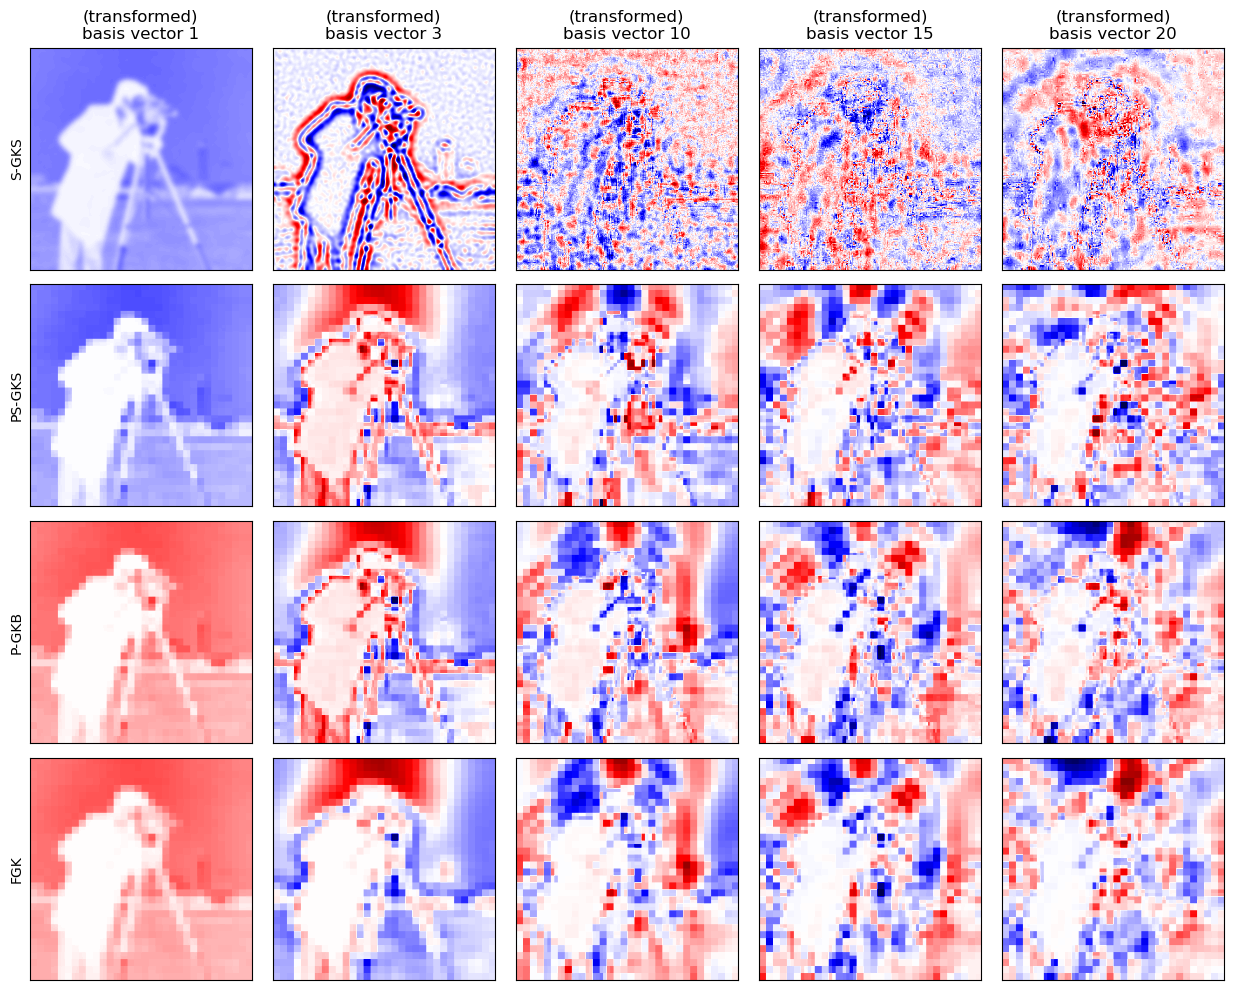

In [170]:
cmap = "seismic"
vbound = 0.1*0.189

kks = [0, 2, 9, 14, 19]

fig, axs = plt.subplots(4,5,figsize=(12.5,10))

for j, kk in enumerate(kks):

    axs[0,j].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[0,j].set_title(f"S-GKS basis vector {kk+1}")
    axs[0,j].set_xticks([])
    axs[0,j].set_yticks([])
    if j == 0:
        axs[0,0].set_ylabel(f"S-GKS")
    axs[0,j].set_title(f"(transformed)\nbasis vector {kk+1}")


for j, kk in enumerate(kks):

    axs[1,j].imshow( ( (pdata["Lopinv"] @ pdata["V"][:,kk])/np.linalg.norm(pdata["Lopinv"] @ pdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[1,j].set_xticks([])
    axs[1,j].set_yticks([])
    if j == 0:
        axs[1,j].set_ylabel(f"PS-GKS")


for j, kk in enumerate(kks):

    axs[2,j].imshow( ( (mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk])/np.linalg.norm(mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[2,j].set_xticks([])
    axs[2,j].set_yticks([])
    if j == 0:
        axs[2,j].set_ylabel(f"P-GKB")



for j, kk in enumerate(kks):

    axs[3,j].imshow( ( mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[3,j].set_xticks([])
    axs[3,j].set_yticks([])
    if j == 0:
        axs[3,j].set_ylabel(f"FGK")


fig.tight_layout()

fig.savefig("2d_camera_basis_vectors_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_basis_vectors_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

In [ ]:
fig = plt.figure(figsize=(18,10))

gs = gridspec.GridSpec(3, 3, figure=fig)

ax1 = fig.add_subplot(gs[2, 2])
ax1.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax1.semilogy(data["lambda_history"], label="S-GKS", color="C5")
ax1.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax1.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax1.semilogy(pdata["lambda_history"], label="PS-GKS", color="C4")
ax1.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax1.set_title("History of $\\lambda$")
ax1.set_xlabel("Iteration index")
ax1.legend()


ax2 = fig.add_subplot(gs[0, 0])
ax2.semilogy(vdata["rre_history"], label="GKS", color="C3")
ax2.semilogy(data["rre_history"], label="S-GKS", color="C5")
ax2.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax2.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax2.semilogy(pdata["rre_history"], label="PS-GKS", color="C4")
ax2.semilogy(respdata["rre_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax2.set_title("RRE")
ax2.set_xlabel("Iteration index")
ax2.legend()


ax3 = fig.add_subplot(gs[0, 1])
ax3.semilogy(vdata["ssim_history"], label="GKS")
ax3.semilogy(data["ssim_history"], label="S-GKS", color="C5")
ax3.semilogy(resdata["ssim_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax3.semilogy(recdata["ssim_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax3.semilogy(pdata["ssim_history"], label="PS-GKS", color="C4")
ax3.semilogy(respdata["ssim_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax3.set_title("SSIM")
ax3.set_xlabel("Iteration index")
ax3.legend()



ax7 = fig.add_subplot(gs[0, 2])
ax7.semilogy(vdata["haar_history"], label="GKS")
ax7.semilogy(data["haar_history"], label="S-GKS", color="C5")
ax7.semilogy(resdata["haar_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax7.semilogy(recdata["haar_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax7.semilogy(pdata["haar_history"], label="PS-GKS", color="C4")
ax7.semilogy(respdata["haar_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax7.set_title("HaarPSI")
ax7.set_xlabel("Iteration index")
ax7.legend()




ax5 = fig.add_subplot(gs[1, :2]) 
ax5.semilogy(1.0/resdata["w"][:int(len(resdata["w"])/2)].reshape(img_shape)[128,:], label="S-GKS (restarting)", color="C5", ls="--")
ax5.semilogy(1.0/respdata["w"][:int(len(resdata["w"])/2)].reshape(img_shape)[128,:], label="PS-GKS (restarting)", color="C4", ls="--")
ax5.set_xlabel("Horizontal cross section at index 128")
ax5.set_title("$1/w$")
ax5.legend()



ax6 = fig.add_subplot(gs[1, 2])
ax6.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax6.semilogy(data["cond_ests"], label="S-GKS", color="C5")
ax6.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", color="C5", ls="--")
ax6.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", color="C5", ls=":")
ax6.semilogy(pdata["cond_ests"], label="PS-GKS", color="C2")
ax6.semilogy(respdata["cond_ests"], label="PS-GKS (restarting)", color="C4", ls="--")
ax6.set_title("Condition number")
ax6.set_xlabel("Iteration index")
ax6.legend()





ax4 = fig.add_subplot(gs[2, :2]) 
ax4.plot(x_true.reshape(img_shape)[128,:], label="Ground truth", color="k", alpha=0.8, lw=0.5)
ax4.plot(vdata["x"].reshape(img_shape)[128,:], label="GKS", color="C3", ls="--")
ax4.plot(resdata["x"].reshape(img_shape)[128,:], label="S-GKS (restarting)", color="C5", ls="--")
ax4.plot(respdata["x"].reshape(img_shape)[128,:], label="PS-GKS (restarting)", color="C4", ls="--")
ax4.set_xlabel("Horizontal cross section at index 128")
ax4.legend()



fig.tight_layout()
# fig.savefig("2d_shepp_performance_mm.png", dpi=250, bbox_inches=None)
# fig.savefig("2d_shepp_performance_mm.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

# Other plots

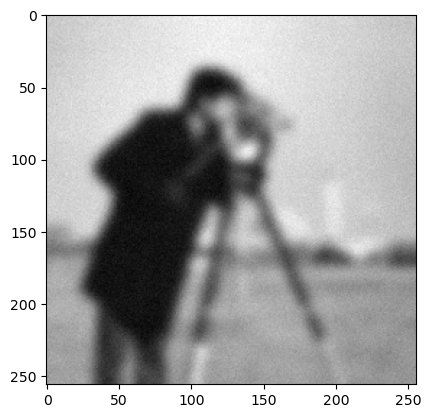

In [135]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

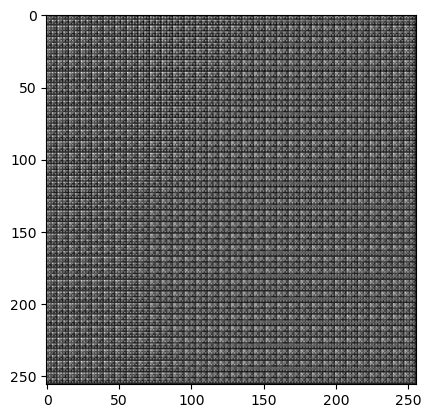

In [136]:
plt.imshow( (L.T @ b).reshape(img_shape), cmap="gray")
plt.show()

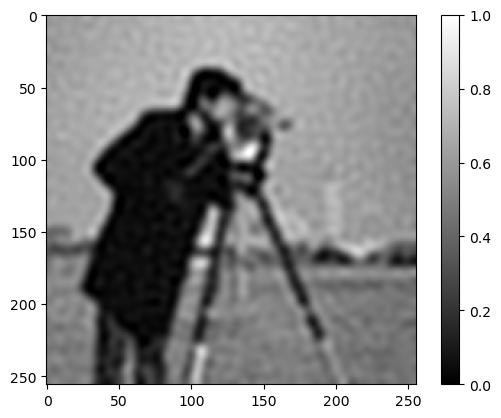

In [116]:
plt.imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

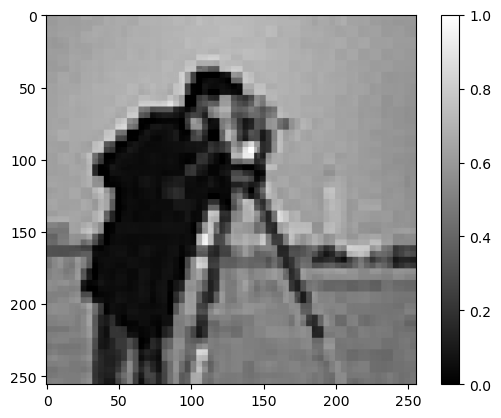

In [117]:
plt.imshow(data["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

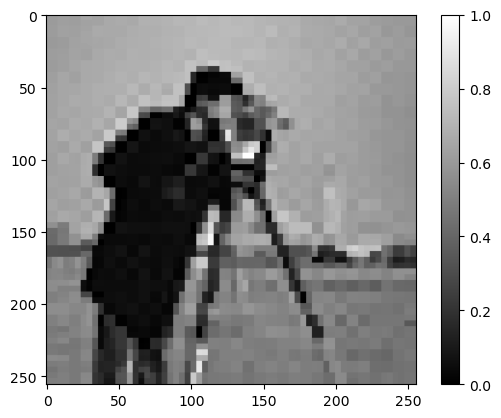

In [118]:
plt.imshow(pdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

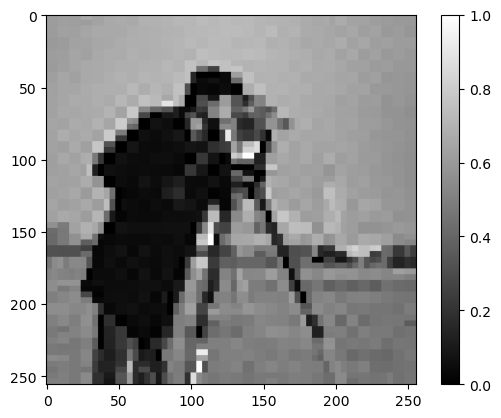

In [119]:
plt.imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

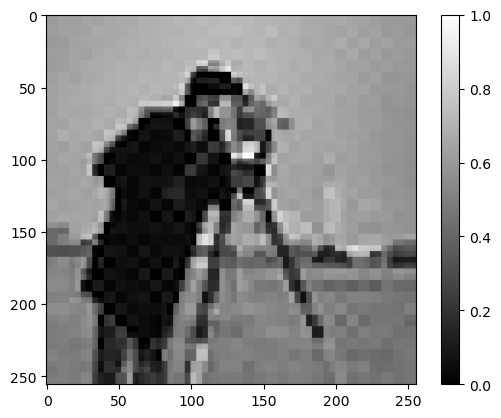

In [120]:
plt.imshow(mmfkdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

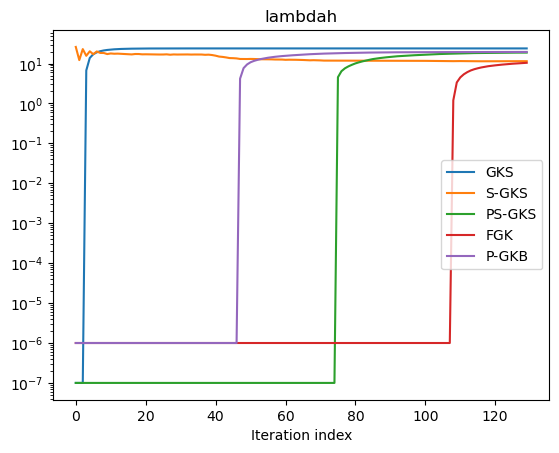

In [121]:
plt.semilogy(vdata["lambda_history"], label="GKS")
plt.semilogy(data["lambda_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["lambda_history"], label="PS-GKS")
plt.semilogy(mmfkdata["lambda_history"], label="FGK")
plt.semilogy(mmgkbdata["lambda_history"], label="P-GKB")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("lambdah")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

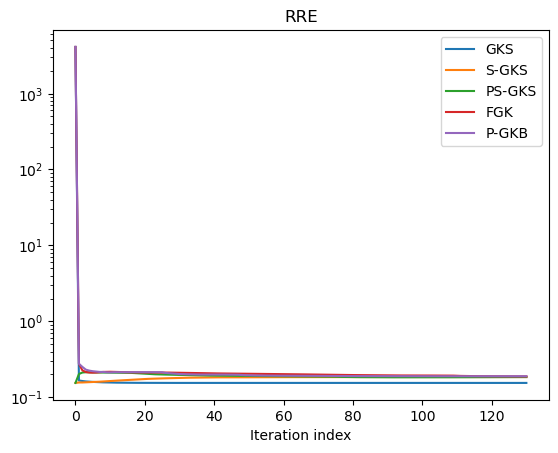

In [122]:
plt.semilogy(vdata["rre_history"], label="GKS")
plt.semilogy(data["rre_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["rre_history"], label="PS-GKS")
plt.semilogy(mmfkdata["rre_history"], label="FGK")
plt.semilogy(mmgkbdata["rre_history"], label="P-GKB")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

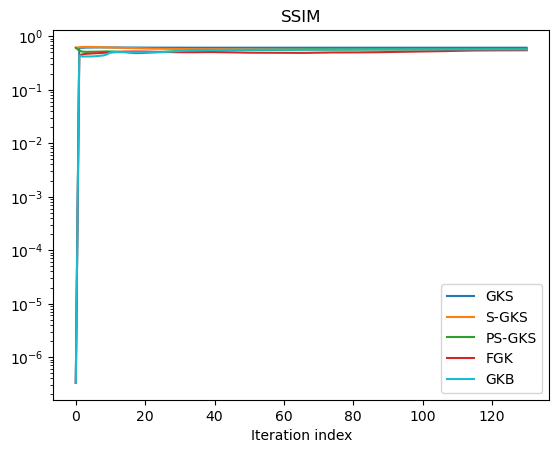

In [125]:
plt.semilogy(vdata["ssim_history"], label="GKS")
plt.semilogy(data["ssim_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["ssim_history"], label="PS-GKS")
plt.semilogy(mmfkdata["ssim_history"], label="FGK")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(mmgkbdata["ssim_history"], label="GKB", color="C9")
plt.title("SSIM")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

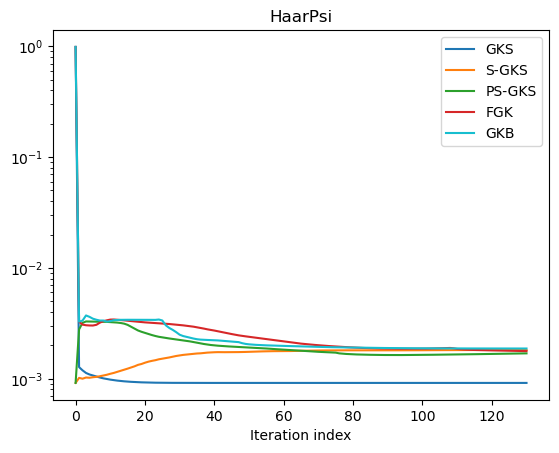

In [126]:
plt.semilogy(1-vdata["haar_history"], label="GKS")
plt.semilogy(1-data["haar_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(1-pdata["haar_history"], label="PS-GKS")
plt.semilogy(1-mmfkdata["haar_history"], label="FGK")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(1-mmgkbdata["haar_history"], label="GKB", color="C9")
plt.title("HaarPsi")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

In [24]:
pdata["haar_history"]

array([0.99977895, 0.99893879, 0.99877378, 0.99870822, 0.99871015,
       0.9987684 , 0.99883229, 0.99887182, 0.99890467, 0.99893616,
       0.99896992, 0.99899804, 0.99902043, 0.99904554, 0.99907053,
       0.99909251, 0.99911082, 0.99912711, 0.99914394, 0.99916236,
       0.99918311, 0.99920906, 0.99923647, 0.99926293, 0.99928414,
       0.9993028 , 0.99932018, 0.99933764, 0.99935618, 0.99937194,
       0.99938765, 0.99940613, 0.99942366, 0.99944045, 0.99945714,
       0.99947115, 0.99948362, 0.99949556, 0.99950773, 0.99951852,
       0.99952721, 0.99953537, 0.99954417, 0.99955255, 0.99956083,
       0.99956818, 0.99957536, 0.99958231, 0.9995889 , 0.99959529,
       0.99960063, 0.99960472, 0.99960906, 0.99961346, 0.99961734,
       0.99962098, 0.99962459, 0.99962742, 0.99962972, 0.9996319 ,
       0.99963382, 0.99963526, 0.99963669, 0.99963862, 0.99964097,
       0.99964298, 0.99964476, 0.99964625, 0.99964718, 0.99964826,
       0.99965394, 0.99966057, 0.99966447, 0.99966765, 0.99967

In [25]:
vdata["haar_history"]

array([9.31203851e-04, 9.99680055e-01, 9.99707518e-01, 9.99728855e-01,
       9.99744216e-01, 9.99755268e-01, 9.99762842e-01, 9.99768336e-01,
       9.99772198e-01, 9.99774815e-01, 9.99776571e-01, 9.99777668e-01,
       9.99778344e-01, 9.99778713e-01, 9.99778885e-01, 9.99778956e-01,
       9.99778968e-01, 9.99778972e-01, 9.99778982e-01, 9.99779013e-01,
       9.99779031e-01, 9.99779029e-01, 9.99779020e-01, 9.99779011e-01,
       9.99779003e-01, 9.99778992e-01, 9.99778986e-01, 9.99778977e-01,
       9.99778971e-01, 9.99778966e-01, 9.99778962e-01, 9.99778960e-01,
       9.99778961e-01, 9.99778962e-01, 9.99778961e-01, 9.99778960e-01,
       9.99778958e-01, 9.99778957e-01, 9.99778955e-01, 9.99778954e-01,
       9.99778953e-01, 9.99778952e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
      

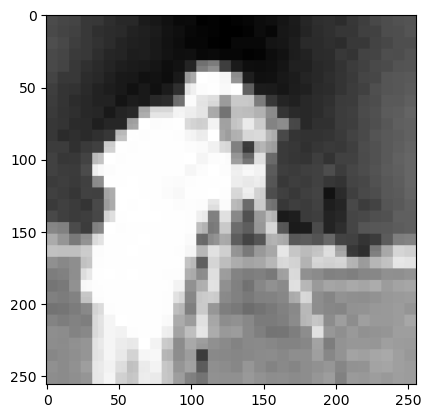

In [127]:
plt.imshow( (pdata["Lopinv"] @ pdata["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

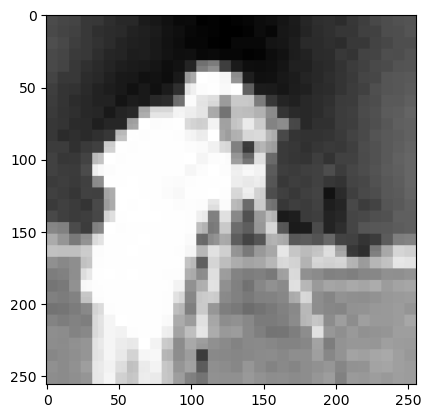

In [128]:
plt.imshow( (pdata["Lopinv"] @ pdata["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

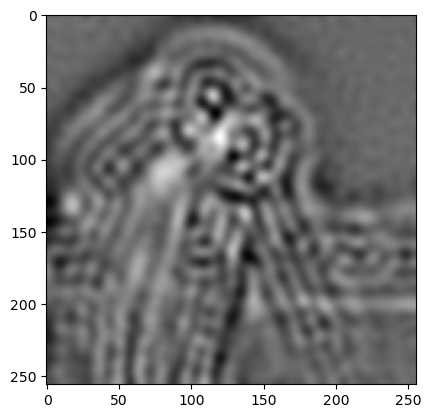

In [129]:
plt.imshow( (vdata["V"][:,5]).reshape(img_shape) , cmap="gray")
plt.show()

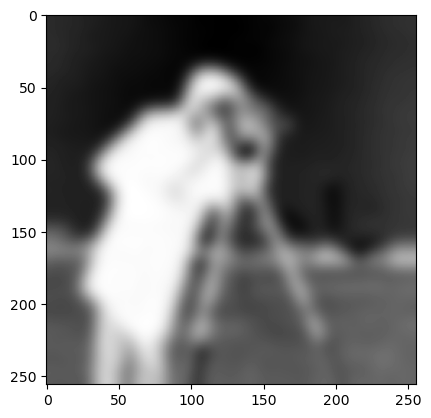

In [130]:
plt.imshow( (data["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

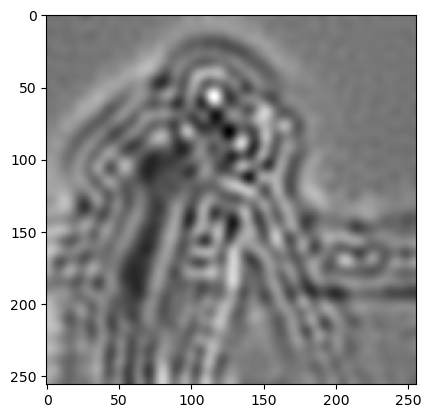

In [131]:
plt.imshow( (data["V"][:,4]).reshape(img_shape) , cmap="gray")
plt.show()

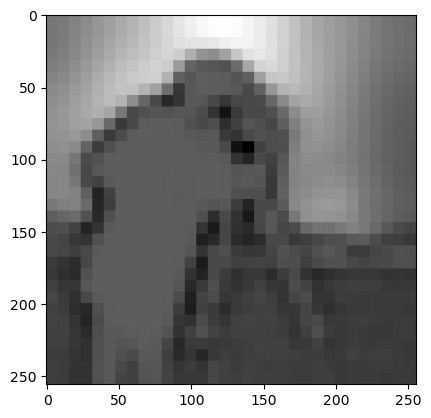

In [132]:
plt.imshow( (mmfkdata["Z"][:,1]).reshape(img_shape) , cmap="gray")
plt.show()

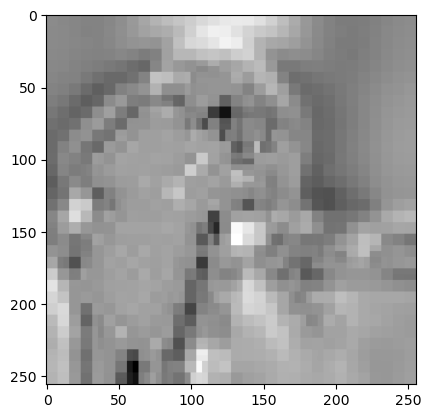

In [133]:
plt.imshow( (mmgkbdata["Lopinv"] @ ( (mmgkbdata["V"][:,4]) ) ).reshape(img_shape) , cmap="gray")
plt.show()

In [134]:
mmgkbdata.keys()

dict_keys(['x', 'V', 'U', 'B', 'w', 'Lopinv', 'lambda_history', 'cond_ests', 'rre_history', 'ssim_history', 'haar_history'])